In [3]:
# Import the librabry relevant to analysis set the layout and save the filepath in variable -

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

FOLDER = r"C:\Users\gagan\Downloads\Portfolios\credit risk Project\pd.scorecard"   # <-- your folder with lc_scored.parquet
CHARTS = os.path.join(FOLDER, "charts")
os.makedirs(CHARTS, exist_ok=True)

LGD_BASE = 0.65                    # ASSUMPTION: share of the original principal lost on a defaulted loan
LGD_RANGE = [0.50, 0.65, 0.85]     # tested range, because LGD is not measured in this data
TERM_MONTHS = 36
print("Setup done")

Setup done


In [4]:
# upload the data via pandas as variables saved in as scored and split the data only required for modeling cuoff is OOT(Out of time)

scored = pd.read_parquet(os.path.join(FOLDER, "lc_scored.parquet"))
print(scored.shape)
print(scored["split"].value_counts().to_dict())

oot = scored[scored["split"] == "OOT"].copy()          # decisions are evaluated on the 2015 loans only
print("OOT loans:", len(oot), "| default rate: %.2f%%" % (100 * oot["bad"].mean()))
oot[["score", "pd", "score_band", "loan_amnt", "int_rate", "bad"]].describe().round(2) 

(546016, 12)
{'OOT': 283025, 'train': 184093, 'validation': 78898}
OOT loans: 283025 | default rate: 14.89%


,score,pd,score_band,loan_amnt,int_rate,bad
count,283025.00,283025.00,283025.00,283025.00,283025.00,283025.00
mean,570.28,0.13,5.39,12805.46,11.28,0.15
std,15.78,0.06,2.91,8059.91,3.69,0.36
min,520.75,0.02,1.00,1000.00,5.32,0.00
25%,558.98,0.09,3.00,6800.00,8.18,0.00
50%,568.86,0.13,5.00,10000.00,11.22,0.00
75%,580.04,0.17,8.00,17000.00,13.66,0.00
max,620.62,0.44,10.00,35000.00,28.99,1.00


In [5]:
# build an interest income function and check it also then check average interest paid on principal


def total_interest(principal, apr, n=TERM_MONTHS):
    """Interest paid over the full term of an amortising loan (monthly instalments)."""
    r = apr / 1200                                   # monthly rate
    payment = principal * r / (1 - (1 + r) ** (-n))  # standard annuity formula
    return n * payment - principal

# Test: a 10,000 loan at 12% for 36 months pays about 1,957 in interest
print("Test, interest on 10,000 at 12%:", round(float(total_interest(10000, 12.0)), 1), "(expected about 1957)")

oot["interest_if_repaid"] = total_interest(oot["loan_amnt"], oot["int_rate"])
print("Average interest if repaid in full: %.1f%% of principal" % (100 * oot["interest_if_repaid"].sum() / oot["loan_amnt"].sum()))

Test, interest on 10,000 at 12%: 1957.2 (expected about 1957)
Average interest if repaid in full: 18.1% of principal


In [6]:
# Cutoff rule: approve if score >= cutoff. The cutoff at the edge of band 1/2 is the "decline band 1" policy.
# cutoff policy as shown define it by score and cuts - sort the data as per score with cut we set-

decline_cut = oot.loc[oot["score_band"] == 2, "score"].min()

def cutoff_row(d, cut):
    appr, rej = d[d["score"] >= cut], d[d["score"] < cut]
    return {
        "cutoff": round(cut, 1),
        "approval_rate_%": 100 * len(appr) / len(d),
        "default_approved_%": 100 * appr["bad"].mean(),
        "default_rejected_%": 100 * rej["bad"].mean() if len(rej) else np.nan,
        "defaults_avoided_%": 100 * (1 - appr["bad"].sum() / d["bad"].sum()),
        "volume_lost_%": 100 * (1 - appr["loan_amnt"].sum() / d["loan_amnt"].sum()),
    }

cuts = sorted([0, 540, 545, 550, 555, 557, 560, 565, 570] + [decline_cut])
cut_tbl = pd.DataFrame([cutoff_row(oot, c) for c in cuts]).set_index("cutoff").round(2)
print("Decline-band-1 cutoff = %.1f" % decline_cut)
cut_tbl

Decline-band-1 cutoff = 551.8


,approval_rate_%,default_approved_%,default_rejected_%,defaults_avoided_%,volume_lost_%
cutoff,,,,,
0.0,100.00,14.89,NaN,0.00,0.00
540.0,98.93,14.73,29.52,2.12,0.56
545.0,96.28,14.39,27.78,6.94,2.13
550.0,91.24,13.81,26.10,15.37,5.45
551.8,88.64,13.53,25.50,19.46,7.28
555.0,83.26,13.00,24.24,27.27,11.26
557.0,79.29,12.60,23.63,32.87,14.34
560.0,72.57,11.99,22.55,41.56,19.81
565.0,60.08,10.84,20.98,56.25,30.72


In [9]:
# AS per LGD we pridict various matrices and compare them to actual ones and also see the band economics of how well
# we are earning after this loss is gone 

oot["el_pred"] = oot["pd"] * LGD_BASE * oot["loan_amnt"]            # expected loss = PD x LGD x exposure
oot["loss_actual"] = oot["bad"] * LGD_BASE * oot["loan_amnt"]       # loss implied by what actually happened
oot["interest_earned"] = oot["interest_if_repaid"] * (1 - oot["bad"])   # interest only comes from loans that repay

g = oot.groupby("score_band")
band_econ = pd.DataFrame({
    "loans": g.size(),
    "exposure_M": g["loan_amnt"].sum() / 1e6,
    "default_%": 100 * g["bad"].mean(),
    "avg_rate_%": g["int_rate"].mean(),
    "predicted_loss_%": 100 * g["el_pred"].sum() / g["loan_amnt"].sum(),
    "actual_loss_%": 100 * g["loss_actual"].sum() / g["loan_amnt"].sum(),
    "interest_income_%": 100 * g["interest_earned"].sum() / g["loan_amnt"].sum(),
})
band_econ["net_%"] = band_econ["interest_income_%"] - band_econ["actual_loss_%"]
band_econ = band_econ.round(2)

tot_exp = oot["loan_amnt"].sum()
print("Whole portfolio, LGD %.0f%%: predicted loss %.2f%% | actual-implied loss %.2f%% | net after losses %.2f%% of exposure" % (
    100 * LGD_BASE, 100 * oot["el_pred"].sum() / tot_exp, 100 * oot["loss_actual"].sum() / tot_exp,
    100 * (oot["interest_earned"].sum() - oot["loss_actual"].sum()) / tot_exp))
band_econ

Whole portfolio, LGD 65%: predicted loss 7.88% | actual-implied loss 9.41% | net after losses 5.51% of exposure


,loans,exposure_M,default_%,avg_rate_%,predicted_loss_%,actual_loss_%,interest_income_%,net_%
score_band,,,,,,,,
1,32151,263.94,25.50,14.46,15.71,17.44,17.13,-0.32
2,29215,283.60,21.27,13.23,12.55,14.67,16.65,1.98
3,28531,301.75,18.71,12.58,10.94,12.95,16.40,3.46
4,27973,321.75,17.04,12.08,9.71,12.01,16.04,4.02
5,28059,348.55,15.70,11.61,8.66,11.15,15.74,4.59
6,27158,361.63,13.86,11.14,7.72,9.68,15.51,5.84
7,27477,392.30,11.64,10.57,6.79,8.12,15.19,7.07
8,27443,420.62,10.16,9.88,5.81,7.03,14.40,7.37
9,27393,443.21,8.02,8.92,4.64,5.50,13.30,7.80


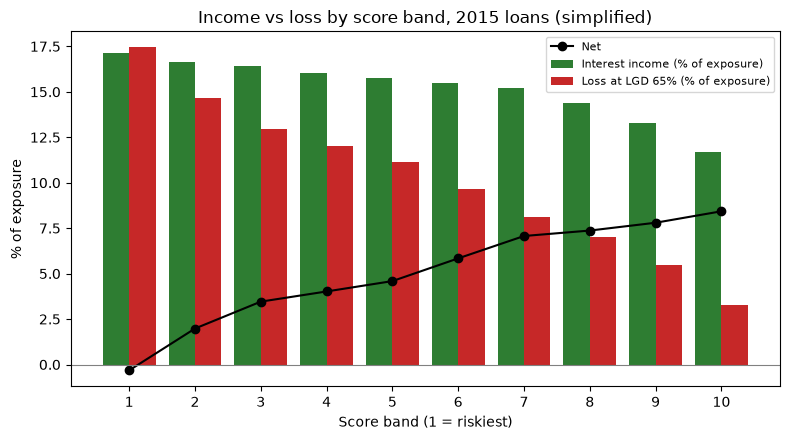

In [10]:
# As we are seeing our band moves to 1 to 10 higher side our income margin of interest also increases at Assum - LSD 65% 

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(1, 11)
ax.bar(x - 0.2, band_econ["interest_income_%"], width=0.4, label="Interest income (% of exposure)", color="#2E7D32")
ax.bar(x + 0.2, band_econ["actual_loss_%"], width=0.4, label=f"Loss at LGD {int(LGD_BASE*100)}% (% of exposure)", color="#C62828")
ax.plot(x, band_econ["net_%"], marker="o", color="black", label="Net")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(x); ax.set_xlabel("Score band (1 = riskiest)"); ax.set_ylabel("% of exposure")
ax.set_title("Income vs loss by score band, 2015 loans (simplified)"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "16_band_economics.png"), dpi=120)
plt.show()

In [11]:
# changes in diff of interest income in various lsd's- 065, 0.50, 0.85

def net_amount(d, lgd):
    """Interest income minus loss (loss = LGD x principal on defaulted loans), in currency units."""
    return (d["interest_earned"] - lgd * d["loan_amnt"] * d["bad"]).sum()

rows = []
for cut in cuts:
    appr = oot[oot["score"] >= cut]
    row = {"cutoff": round(cut, 1)}
    for lgd in LGD_RANGE:
        row[f"change_LGD{int(lgd*100)}_M"] = (net_amount(appr, lgd) - net_amount(oot, lgd)) / 1e6   # vs approving everyone
    rows.append(row)
sens = pd.DataFrame(rows).set_index("cutoff").round(1)
sens

,change_LGD50_M,change_LGD65_M,change_LGD85_M
cutoff,,,
0.0,0.0,0.0,0.0
540.0,-0.6,0.3,1.6
545.0,-2.4,1.0,5.5
550.0,-7.0,1.2,12.0
551.8,-9.8,0.8,15.0
555.0,-17.8,-2.3,18.4
557.0,-23.6,-4.3,21.5
560.0,-35.9,-10.4,23.5
565.0,-62.4,-25.8,23.0


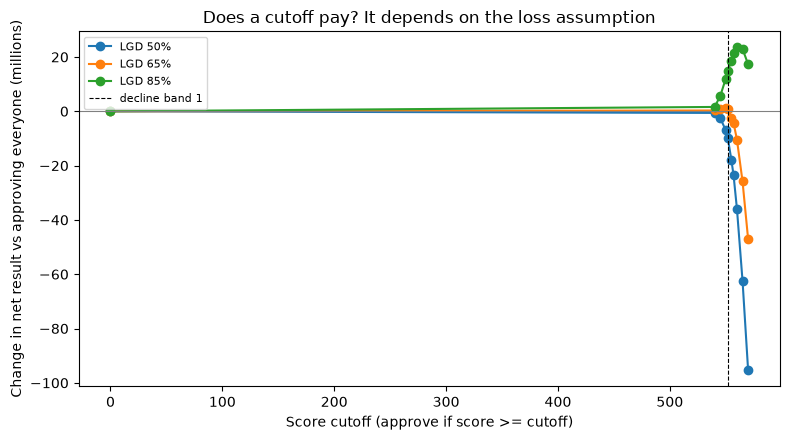

In [12]:
# Does cutoff pay or nor depends on loss assumptions

fig, ax = plt.subplots(figsize=(8, 4.5))
for col, lab in zip(sens.columns, [f"LGD {int(l*100)}%" for l in LGD_RANGE]):
    ax.plot(sens.index, sens[col], marker="o", label=lab)
ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(decline_cut, color="black", linestyle="--", linewidth=0.8, label="decline band 1")
ax.set_xlabel("Score cutoff (approve if score >= cutoff)"); ax.set_ylabel("Change in net result vs approving everyone (millions)")
ax.set_title("Does a cutoff pay? It depends on the loss assumption"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "17_cutoff_sensitivity.png"), dpi=120)
plt.show()

In [13]:
#define function for making decisions

def tier(b):
    if b == 1: return "1. Decline"
    if b in (2, 3): return "2. Approve with review / higher price"
    return "3. Approve"

oot["tier"] = oot["score_band"].map(tier)
gt = oot.groupby("tier")
policy = pd.DataFrame({
    "bands": gt["score_band"].agg(lambda s: f"{s.min()}-{s.max()}"),
    "share_of_loans_%": 100 * gt.size() / len(oot),
    "default_%": 100 * gt["bad"].mean(),
    "avg_rate_%": gt["int_rate"].mean(),
    "net_%_of_exposure": 100 * (gt["interest_earned"].sum() - LGD_BASE * gt.apply(lambda d: (d["loan_amnt"] * d["bad"]).sum())) / gt["loan_amnt"].sum(),
}).round(2)

appr = oot[oot["score_band"] > 1]
print("POLICY: decline band 1 (score below %.0f)" % decline_cut)
print("  Approval rate:            %.1f%%" % (100 * len(appr) / len(oot)))
print("  Default rate:             %.2f%% -> %.2f%%" % (100 * oot["bad"].mean(), 100 * appr["bad"].mean()))
print("  Defaults avoided:         %.1f%%" % (100 * (1 - appr["bad"].sum() / oot["bad"].sum())))
print("  Exposure turned away:     %.1f%%" % (100 * (1 - appr["loan_amnt"].sum() / tot_exp)))
for lgd in LGD_RANGE:
    print("  Net result change at LGD %d%%: %+.1f million" % (lgd * 100, (net_amount(appr, lgd) - net_amount(oot, lgd)) / 1e6))
policy

POLICY: decline band 1 (score below 552)
  Approval rate:            88.6%
  Default rate:             14.89% -> 13.53%
  Defaults avoided:         19.5%
  Exposure turned away:     7.3%
  Net result change at LGD 50%: -9.8 million
  Net result change at LGD 65%: +0.8 million
  Net result change at LGD 85%: +15.0 million


,bands,share_of_loans_%,default_%,avg_rate_%,net_%_of_exposure
tier,,,,,
1. Decline,1-1,11.36,25.50,14.46,-0.32
2. Approve with review / higher price,2-3,20.40,20.00,12.91,2.74
3. Approve,4-10,68.24,11.59,10.26,6.65


In [14]:
cut_tbl.to_csv(os.path.join(FOLDER, "cutoff_table.csv"))
band_econ.to_csv(os.path.join(FOLDER, "band_economics.csv"))
sens.to_csv(os.path.join(FOLDER, "cutoff_sensitivity.csv"))
policy.to_csv(os.path.join(FOLDER, "policy_tiers.csv"))
print("Saved: cutoff_table.csv, band_economics.csv, cutoff_sensitivity.csv, policy_tiers.csv in", FOLDER)

Saved: cutoff_table.csv, band_economics.csv, cutoff_sensitivity.csv, policy_tiers.csv in C:\Users\gagan\Downloads\Portfolios\credit risk Project\pd.scorecard
